In [1]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing import BackgroundEraser
import glob
from pipeline.feature_learning.vae import VAE
from PIL import Image
from torchvision import transforms
from pipeline.feature_learning.vae import resize_with_padding
from pipeline.preprocessing import Repair
from pipeline.preprocessing import Normalizer

# PIPELINE

## Preprocessing

### Shard selection and  background cleaning

In [5]:

#image_paths = glob.glob("/caa/Homes01/alaczko/Diploma/Diploma/data/raw/00_Selection ML/2012_Survey Gladiatorenschule/**/*.jpg", recursive=True)
image_path= "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256/"

print(f"Found {len(image_path)} images.")
 
br=BackgroundEraser(input_path=image_path, batch_size=32, num_workers=16)

erased=br.run()

Found 67 images.
Output path for step BackgroundEraser : ../data/pipeline/default_run/PreprocessingStep/BackgroundEraser
_detectshards


Detecting shards:   0%|          | 0/67 [00:00<?, ?image/s]


FileNotFoundError: No images or videos found in /tmp/yolo_batch_s6anld_z. Supported formats are:
images: {'avif', 'jpeg', 'jpg', 'png', 'heif', 'dng', 'tiff', 'tif', 'mpo', 'bmp', 'heic', 'jp2', 'webp'}
videos: {'webm', 'm4v', 'ts', 'mov', 'wmv', 'gif', 'mkv', 'mpg', 'asf', 'mpeg', 'avi', 'mp4'}

### Resize & Crop

In [6]:
crop_step = Normalizer(input_path=image_path, background_color=(0, 0, 0))

cropped= crop_step.run()

Output path for step Normalizer : ../data/pipeline/default_run/PreprocessingStep/Normalizer


Normalizing images:  11%|█         | 502/4620 [00:09<01:21, 50.32image/s]


KeyboardInterrupt: 

### Enhancing Picture Quality

In [4]:
repair_step = Repair(
    input_path=erased,
    max_distance=20,
    output_thickness=3,   # ← ez az új paraméter
)

result_path = repair_step.run()

Output path for step Repair : ../data/pipeline/default_run/PreprocessingStep/Repair


Repairing images:   0%|          | 0/13 [00:00<?, ?image/s]

Repairing images: 100%|██████████| 13/13 [00:00<00:00, 17.12image/s]


## Feature Learning

In [ ]:
vae = VAE(input_path="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256", f=4, n=3, s=1, k=128)  # k=128 latent dimension
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

results = vae.run('train_model', epochs=1000, lr=1e-6, batch_size=128)

torch.save(vae.state_dict(), "../models/feature_learning/roco.pt")

Output path for step VAE : ../data/pipeline/default_run/Module/VAE
Dataset size: 4620
[epoch 1] loss: 5821219.436 | beta: 0.000
[epoch 2] loss: 5817566.230 | beta: 0.008
[epoch 3] loss: 5813861.127 | beta: 0.016
[epoch 4] loss: 5809981.715 | beta: 0.024
[epoch 5] loss: 5805630.608 | beta: 0.032
[epoch 6] loss: 5800250.255 | beta: 0.040
[epoch 7] loss: 5792806.414 | beta: 0.048
[epoch 8] loss: 5781475.159 | beta: 0.056
[epoch 9] loss: 5763967.806 | beta: 0.064
[epoch 10] loss: 5738129.416 | beta: 0.072
[epoch 11] loss: 5702396.390 | beta: 0.080
[epoch 12] loss: 5657019.373 | beta: 0.088
[epoch 13] loss: 5603229.620 | beta: 0.096
[epoch 14] loss: 5543596.667 | beta: 0.104
[epoch 15] loss: 5479991.506 | beta: 0.112
[epoch 16] loss: 5414531.107 | beta: 0.120
[epoch 17] loss: 5348415.675 | beta: 0.128
[epoch 18] loss: 5282126.351 | beta: 0.136
[epoch 19] loss: 5216623.884 | beta: 0.144
[epoch 20] loss: 5152015.184 | beta: 0.152
[epoch 21] loss: 5088156.709 | beta: 0.160
[epoch 22] loss: 502

[epoch 1] loss: 1353931.506
[epoch 2] loss: 1353410.569
[epoch 3] loss: 1352911.637
[epoch 4] loss: 1352423.925
[epoch 5] loss: 1351923.169
[epoch 6] loss: 1351422.119
[epoch 7] loss: 1350913.719
[epoch 8] loss: 1350395.262
[epoch 9] loss: 1349917.094
[epoch 10] loss: 1349405.206
torch.Size([304, 256])

In [13]:
results = vae.extract_features(folder="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256", batch_size=128)

In [17]:
results.to_csv("../data/pipeline/default_run/features.csv", index=False)

### Testing Feature Learning

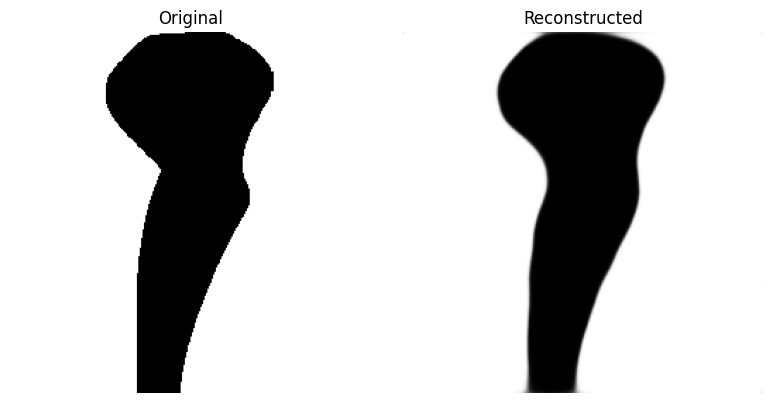

In [9]:
#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
])

img_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot_rim_256/Rims_256/POHL70-101.453.png"
original_img = Image.open(img_path)
input_tensor = transform(original_img).unsqueeze(0).to(device) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae(input_tensor)

orig_np = input_tensor.squeeze().cpu().numpy()
recon_np = reconstructed.squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()